# Stiffness a.k.a "what makes your simulation slow"

An ODE problem is stiff when an **explicit time step is dictated by stability requirements**, not accuracy requirements.
Roughly speaking, some processes in the system are moving on **different time scales** than others.
Smaller time steps mean more computations and **therefore longer simulations**.

**Chromatography models are generally stiff**: they can contain processes on very different time scales.
Binding for example may happen much faster than dispersion.

### What this means for CADET
1. **time integration must be implicit** to escape excessive explicit time step stability constraints
2. implicit integration is only **limited by accuracy, not stability** / stiffness
3. but implicit **time integration costs** a lot more per time step because a **nonlinear system must be solved**
4. also **strong gradients** in the solution often require more time steps even for implicit time integration


## Stiffness: Exemplary system with two time scales

Two coupled processes, written as a linear system of ODEs:

$$
\frac{\mathrm{d}}{\mathrm{d}t}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix}
=
\begin{pmatrix} -500.5 & 499.5 \\ 499.5 & -500.5 \end{pmatrix}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix},
\qquad
\begin{pmatrix} y_1(0) \\ y_2(0) \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}
$$

Nothing about those four numbers looks dramatic. The analytical solution shows what they mean:

$$
y(t) \;=\; \underbrace{\tfrac{1}{2}\, e^{-t} \begin{pmatrix} 1 \\ 1 \end{pmatrix}}_{\text{slow: seconds}}
\;+\; \underbrace{\tfrac{1}{2}\, e^{-1000\,t} \begin{pmatrix} 1 \\ -1 \end{pmatrix}}_{\text{fast: milliseconds}}
$$

**One process decays over seconds, the other over milliseconds**.
The next cell shows the solution: After roughly five milliseconds the fast one is gone, and what is left is a plain exponential decay.

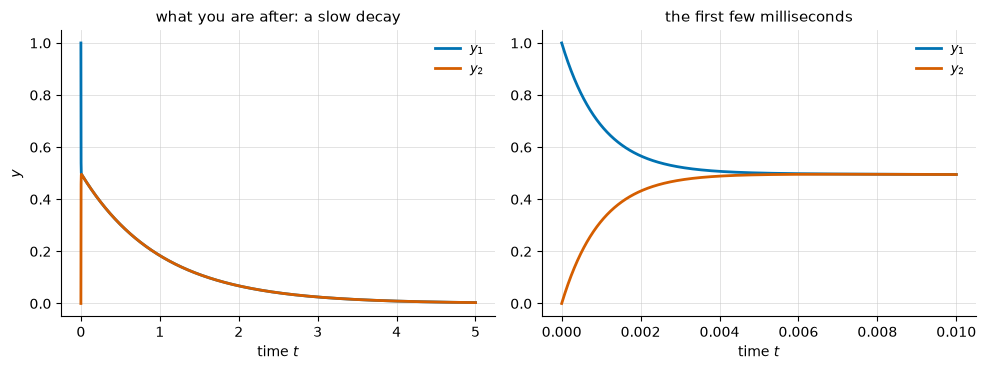

In [1]:
import numpy as np
import utility.stiffness_demos as demos

demos.plot_two_scale_solution(t_end=5.0, zoom_end=0.01);

### Explicit vs. Implicit time integration

The two simplest implicit and explicit time integration methods:

- **explicit Euler**, $\;y_{n+1} = y_n + h\,A\,y_n\;$ —> explicit formulation: the new value is written down from the old one.
- **implicit Euler**, $\;(I - h\,A)\,y_{n+1} = y_n\;$ —> a system of equations has to be solved for every single step.

Both require a time step $h>$.
From the solution perspective, we care about the slow scale, so a step of $h = 0.1$ should be sufficiently accurate, giving us fifty steps for the whole curve. 

We test both methods with different time step sizes and gather their accuracy in the table below.

In [2]:
from ipywidgets import interact

show_euler = demos.make_time_step_explorer()

interact(show_euler, **show_euler.sliders);

interactive(children=(SelectionSlider(continuous_update=False, description='time step', options=(('0.2', 0.2),…

### What is happening here

- At coarse time steps, the implicit method is less accurate and improves with refinement of h
- The explicit method however blows up, errors accumulate towards infinity
- Only at the fine time step, explicit time stepping is suddenly accurate. There is no inaccurate range.

> **An implicit method chooses its step size for accuracy. An explicit method has its step size dictated by stability.**

The **fast mode per step** is the factor by which one step multiplies the fast component. For explicit Euler it is $|1 + h\lambda_\text{fast}|$, which passes 1 at $h = 2/|\lambda_\text{fast}| = 0.002$; for implicit Euler it is $1/|1 - h\lambda_\text{fast}|$, which is below 1 for every $h$ there is.

The **fastest** process in the system dictates the explicit time step, whether its important or not. Here, the fast process is over after five milliseconds, and it still dictates the step size for the remaining five seconds.

<details>
<summary><b>Click to learn more about stability</b></summary>

The behaviour of a linear system is governed by the **eigenvalues** of its matrix, here

$$\lambda_{\text{slow}} = -1, \qquad \lambda_{\text{fast}} = -1000,$$

which are exactly the two decay rates in the analytical solution above. One step of a method multiplies each eigen-component by an amplification factor $R(z)$, where $z = h\lambda$ is the **scaled eigenvalue**:

$$R_{\text{explicit}}(z) = 1 + z, \qquad\qquad R_{\text{implicit}}(z) = \frac{1}{1-z}.$$

A component stays bounded if $|R(z)| \le 1$, and the set of all $z$ for which that holds is the method's **stability region**.

For explicit Euler, $|1 + z| \le 1$ is a disk of radius one around $-1$, so we need $-2 < h\lambda < 0$. With $\lambda = -1000$ that is $h < 0.002$, and our $h = 0.1$ is fifty times too large: the fast component gets multiplied by $1 - 100 = -99$ every step. Runge-Kutta 4 has a larger region, but it is still bounded — no explicit method escapes this.

For implicit Euler, $|1/(1-z)| \le 1$ holds for *every* $z$ in the left half plane. Every decaying process is stable at every step size. That is what you buy with the solve in every step.

<img src="data/img/stability_regions.png" width="860" alt="stability regions of explicit and implicit methods">

The ratio $|\lambda_{\text{fast}}| / |\lambda_{\text{slow}}| = 1000$ is sometimes called the **stiffness ratio**. It is a crude indicator, but it carries the right intuition: the further apart the time scales, the wider the gap between the step size your result needs and the step size your method is allowed.

</details>

### What it costs to be stable

The implicit time integration has to solve the system 
$\;(I - h\,A)\,y_{n+1} = y_n\;$
meaning the matrix $(I - h\,A)$ has to be inverted.
Depending on the size and nonlinearity of the matrix, this becomes computationally expensive.
> **That is the trade.** The stability constraint is removed, and in exchange every step becomes expensive.

### What this means for CADET

> **In CADET, stiffness never breaks your simulation but bills you for it.**

> **The computational time is mostly spent on solving the nonlinear system Jacobian, which becomes more expensive the larger the matrix is and the more connected and nonlinear the equations are.**

## Putting a number on "fast" and "slow"

So far "fast" and "slow" have been adjectives. From here on they are numbers, and the number is a **rate in $1/\mathrm{s}$**: bigger means faster. You get one for every process by dividing its coefficient by the **length or surface it acts over**:

| process | rate | discretized rate
|---|---|---|
| convection | $u / L$ | $u / L$ |
| dispersion | $D / L^{2}$ | $D / L^{2}$ |
| pore diffusion | $D / (R^p)^{2}$ | $D / (R^p)^{2}$ |
| film mass transfer | $3 k_f / R^p \cdot (1-\varepsilon)/\varepsilon$ | $3 k_f / R^p \cdot (1-\varepsilon)/\varepsilon$ |
| binding kinetics | $k_a c + k_d$ | $k_a c + k_d$ |

### Which length? Two answers, and the second one is yours

The rate and discretized rate refer to the physical lenght and the numerical length coming from the spatial grid, which is the one the time integration method "sees", so its the one that matters.
Refining a grid therefore **creates faster processes** and thus impacts the stiffness of the system.

### What about binding, which has no grid?

A binding or reaction term is a local equation; no spatial derivative, no $\Delta z$. But it still imprints a **length** on the solution, by competing with transport: while material travels at $u$, the binding relaxes at $k$, so the mass transfer zone is about

$$L_\mathrm{MTZ} \sim u/k .$$

Comparing rates is then the same as comparing lengths, because $\;k \big/ (u/\Delta z) = \Delta z / L_\mathrm{MTZ}$. A fast binding is one whose mass transfer zone has shrunk towards the size of a cell.

### The rule

> **Find the largest rate in the table and compare it with the rate of the result you want to look at.** A chromatogram with features a few seconds wide needs about $1\,\mathrm{s^{-1}}$. Processes far above that, which you cannot see in the result anyway, are what cost you.

Two things this corrects:

- **A slow process never makes a system stiff.** "Stiffness is the ratio of fastest to slowest" is a common phrasing and it is misleading: adding something very slow costs nothing, an implicit integrator just carries it. Only the top of the table matters.
- **The comparison is against the grid, not against the other physics.** A binding reaction is not fast because it beats pore diffusion. It is fast when it beats everything already there, and in a well resolved column that is usually convection across one cell.

<details>
<summary><b>Click to learn more: in what sense these numbers are the eigenvalues</b></summary>

Section 4.2 showed that the step size responds to the eigenvalues of the system. These rates are order of magnitude estimates of exactly those, for the *spatially discretized* system:

- a relaxation term $\mathrm{d}y/\mathrm{d}t = -k\,(y-y_\infty)$ has the eigenvalue $-k$ exactly;
- a discretized diffusion operator has eigenvalues spread over $-\mathcal{O}(D/\Delta z^{2})$;
- a discretized convection operator has eigenvalues of magnitude $\mathcal{O}(u/\Delta z)$, and for DG of degree $p$ the node spacing within an element is finer than $\Delta z$, which is why high order discretizations produce larger ones.

They are estimates. The point is to see which row is the largest, not to get three digits right: a factor of two does not matter here, a factor of a thousand does.

</details>


In [3]:
import utility.setting_Col1D_langmuir_realistic as column
import utility.time_scales as time_scales

# The three component separation of the next notebook, on 25 finite volume
# cells. No simulation is run here: these are the model's own parameters
# divided by the model's own lengths. The velocity has to be passed in, because
# the model stores a flow rate and a geometry, not a velocity.
model = column.get_model(n_elements=25, kinetics_factor=1.0)

time_scales.characteristic_rates(
    model.input.model.unit_001,
    velocity=column.interstitial_velocity(),
    feed_concentration=column.LOADING,
)

,process,rate / s^-1,set by,time scale / s
0,binding (Langmuir),1.400000,physics,0.714286
1,film mass transfer,1.135135,physics,0.880952
2,"convection, one grid node",0.283784,discretization,3.523810
3,"convection, whole column",0.011351,physics,88.095238
4,"axial dispersion, one grid node",0.006250,discretization,160.000000
5,"axial dispersion, whole column",0.000010,physics,100000.000000


Read it from the top. The fastest process here is the **binding** at $1.4\,\mathrm{s^{-1}}$, just ahead of film mass transfer at $1.1\,\mathrm{s^{-1}}$. Convection across one of the 25 cells runs at $0.28\,\mathrm{s^{-1}}$, while convection through the whole column takes 88 s.

And what do we actually need to resolve? The narrowest peak of this separation is about three minutes wide, so roughly $0.006\,\mathrm{s^{-1}}$. The fastest thing in the model is therefore some 250 times faster than the feature we are trying to see, and the slowest, dispersion over the column length, is another five decades below that.

The next notebook takes this exact model and raises the binding rate alone, decade by decade, to find out what the integrator charges for it.

***

# Act 2 — where those rates actually sit

A rate is a number; what the integrator reacts to is an **eigenvalue**. Section 4.2 showed that a method is stable on a region of the complex plane, and that the step size is safe as long as $z = h\lambda$ stays inside it.

So the question for a chromatography model is simply: **where in that plane do its terms land?**

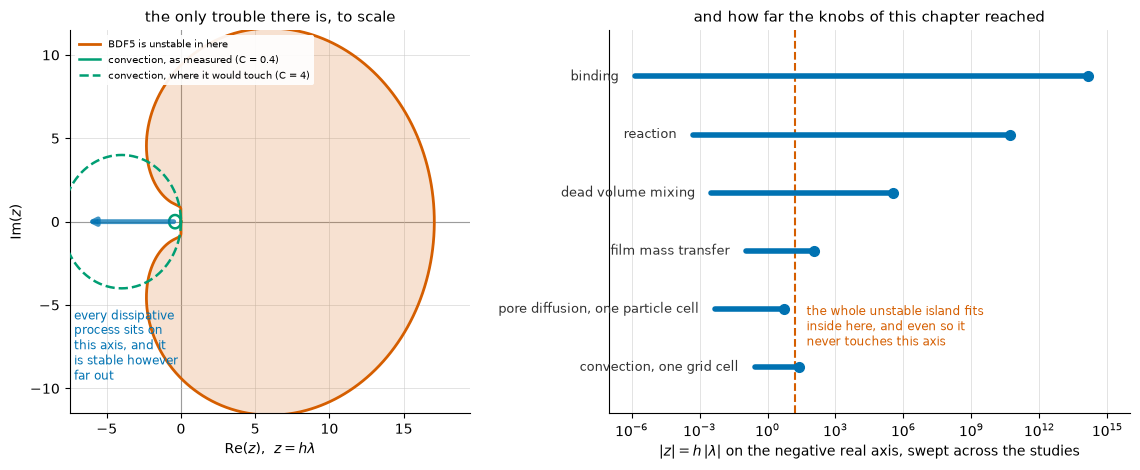

In [6]:
import utility.stiffness_demos as demos

demos.plot_where_the_eigenvalues_go();

**Every dissipative process puts its eigenvalue on the negative real axis**: binding relaxation, film transfer, pore and axial diffusion, reactions, a stirred dead volume. On that axis BDF is stable at *any* magnitude. The knobs of this chapter pushed eigenvalues out to $|z| \approx 10^{14}$, which is not closer to trouble but a hundred trillion times further from it.

**Convection is the one operator that leaves the axis**, because a first derivative is anti-self-adjoint. Upwinding puts its spectrum on a circle through the origin, and that circle *does* reach the unstable region — at a Courant number of about 4. The most convection-dominated run in this chapter, a Péclet number of $10^9$ at polynomial degree 15, ran at **C ≈ 0.4**.

### The five regions IDAS switches between

IDAS does not run one method. It runs backward differentiation formulas of order one to five and changes the order as it goes, so "the stability region" above is really five of them.

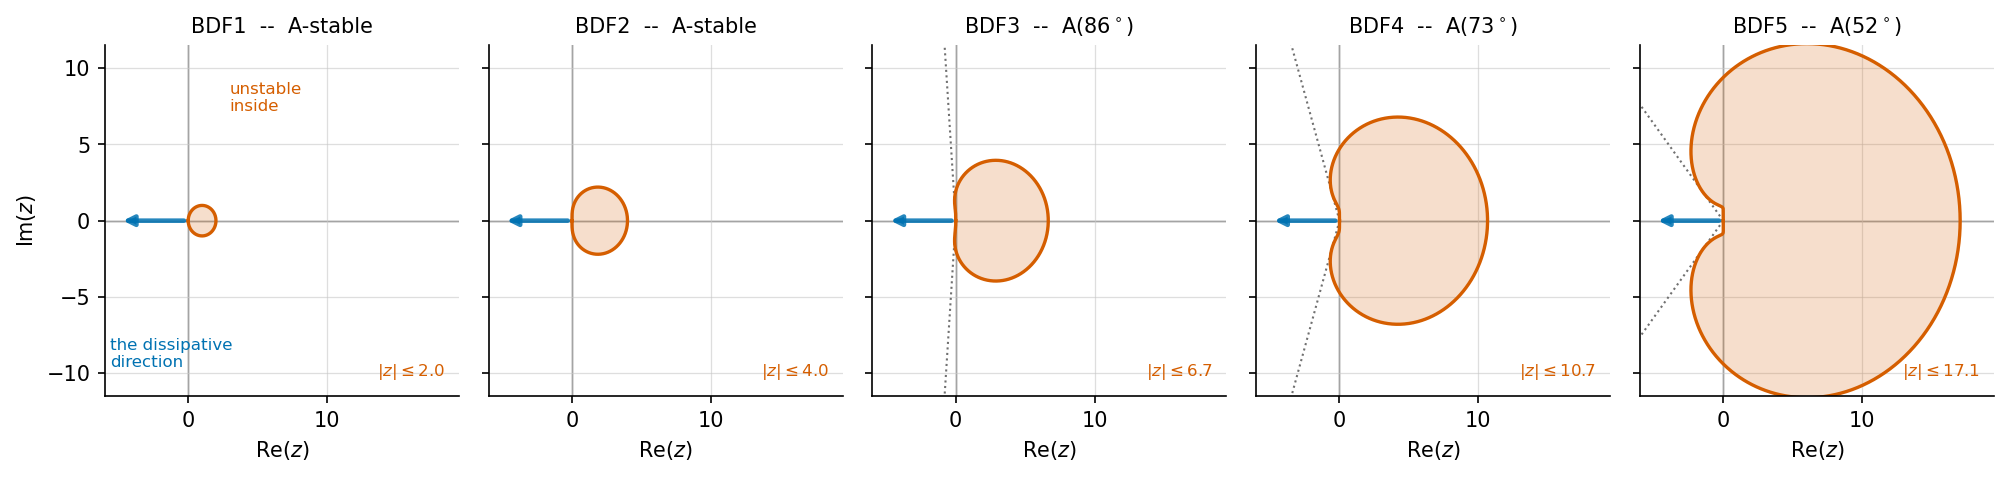

In [10]:
from IPython.display import Image

# The figure below is the output of this call, saved to the repository because
# the A(alpha) angle in each panel title is found by root finding and may take
# minutes to compute. Uncomment to regenerate it.
#
# demos.plot_bdf_stability_regions()[0].savefig(
#     'data/img/bdf_stability_regions.png', dpi=150, bbox_inches='tight')

Image(filename='data/img/bdf_stability_regions.png')

The dotted rays mark the $A(\alpha)$ edge: the widest sector around the negative real axis that the order is stable in at *every* magnitude. Three things are worth reading off, and the first is the one that is easy to get wrong.

**The unstable set is a bounded island, not a sector.** It is tempting to summarise BDF5 as "stable within 52° of the negative real axis", and then to expect that an eigenvalue outside that wedge gets you into trouble as soon as it is large enough. It does not. Outside the wedge the method is unstable only for a *window* of magnitudes: the whole island fits inside $|z| \leq 17.1$, so pushing $h\lambda$ past it comes out stable on the other side. Danger is a window you pass through, not a threshold you cross — which means neither a very small nor a very large step is the risk, an intermediate one is.

**A larger island is what a higher order costs.** Each order buys an order of accuracy and pays with a bigger unstable set, from $|z| \leq 2$ at BDF1 to $|z| \leq 17.1$ at BDF5. This is why lowering the order is a sensible response to rejected steps: BDF1 and BDF2 are A-stable outright, and nothing in the left half plane can destabilise them.

**No island touches the negative real axis, at any order.** Sampling 2000 magnitudes across eighteen decades for all five orders returns not one unstable point. BDF5's island reaches furthest left, to $\mathrm{Re}(z) \approx -2.33$, and even at that point it is $|\mathrm{Im}(z)| \approx 4.5$ clear of the axis.


### What that predicts, and what was measured

If the picture above is right, making a dissipative process faster should cost nothing at all. Four studies tested exactly that, each sweeping one rate as far as the model allowed:

| study | knob | step count |
|---|---|---|
| binding kinetics | 14 decades of $k_a$, $k_d$ | 1646 → 1668, and **exactly flat** over the last nine decades |
| a bulk reaction | 11 decades | +1 % |
| a stirred dead volume | 8 decades | +0.9 % |
| the particle | 1 → 32 radial cells | 2920 → **1379**, i.e. *down* |

The binding sweep is the sharpest: past $10^{6}\ \mathrm{s^{-1}}$ the step count stops changing at all, and equals the rapid-equilibrium DAE's step count exactly.

<details>
<summary><b>Click to learn more: why a fast process costs nothing once it is fast</b></summary>

The naive expectation is that a fast process means large $\mathrm{d}^k y/\mathrm{d}t^k$, hence large truncation error, hence small steps. That is true only while the fast mode is *moving*.

The error estimate is a property of the **solution**; the stability region is a property of the **operator**. A fast mode leaves the solution; it never leaves the operator. That asymmetry is the whole answer, and it is why the same mode can cost an explicit method everything and an implicit one nothing.

In a column the fast mode is never really excited. Binding is driven by transport, which is slow, so the adsorbed phase is **slaved** to the liquid: $q$ tracks $q^*(c)$ and $\mathrm{d}q/\mathrm{d}t$ is set by how fast $c$ changes, not by $k$. The solution sits on the slow manifold, so every derivative the error estimator sees is slow. That the kinetic model reproduces the DAE's step count exactly is the proof — IDAS is already integrating the manifold.

You do pay in two places: when a fast mode is genuinely excited by a discontinuity (about 48 steps per section boundary, measured), and per step, forever, because the fast mode is still in the Jacobian.

</details>

<details>
<summary><b>Click to learn more: why each term lands where it does</b></summary>

Split the Jacobian into a symmetric and a skew-symmetric part, $J = H + S$ with $H = \tfrac12(J + J^{\top})$ and $S = \tfrac12(J - J^{\top})$. **Bendixson's theorem** then bounds the two directions separately:

$$\lambda_{\min}(H) \;\le\; \mathrm{Re}(\lambda) \;\le\; \lambda_{\max}(H), \qquad \mathrm{Im}(\lambda) \in \text{range of } \tfrac{1}{i}S .$$

The symmetric part decides how far **left** an eigenvalue sits; the skew part decides how far **off the axis**. Everything below follows from which of the two a given term contributes to.

**Diffusion is self-adjoint.** $\int u\,\partial_z^2 v = \int v\,\partial_z^2 u$, so the discretized operator is a symmetric matrix, and symmetric real matrices have real eigenvalues. Negative semi-definite, so they are non-positive. This covers axial dispersion and pore diffusion.

**Exchange and relaxation are symmetrizable.** Film transfer between bulk and pore liquid is

$$\begin{pmatrix}-a & a\\ b & -b\end{pmatrix},$$

whose rows sum to zero because material is conserved. Its eigenvalues are $0$ and $-(a+b)$, both real. The same holds for any network of positive exchange rates: a positive diagonal rescaling makes it symmetric.

**Adsorption is the same structure.** Linearizing the binding flux with $A = \partial F/\partial c$ and $B = -\partial F/\partial q$, the block for one component at one node is

$$J = \begin{pmatrix}-\beta A & \beta B\\ A & -B\end{pmatrix}, \qquad \det J = \beta A B - \beta A B = 0 .$$

The determinant vanishes because binding conserves $c + q/\beta$. One eigenvalue is therefore exactly zero — the conserved combination — and the other is the trace, $-(\beta A + B)$: real, negative, and equal to the rate the table reports. Evaluating this numerically for *competitive* three component Langmuir, where the components fight over the same sites, gives a 6×6 block with eigenvalues $-1.59$, $-1.29$, $-1.14$ and three exact zeros, with a largest imaginary part of $0$.

**Particle size enters twice, and both are of this kind.** Film transfer scales as $3k_f/r_p$, the specific surface area, and pore diffusion as $D_p/\Delta r^2$. Shrinking a particle therefore pushes real eigenvalues further left and contributes nothing at all to the skew part — which is why the particle study found it free.

**Convection is the exception, because the first derivative is anti-self-adjoint.** $\int u\,\partial_z v = -\int v\,\partial_z u$, so a central discretization is a *skew* matrix, and real skew matrices have **purely imaginary** eigenvalues: rotation without decay. Upwinding adds artificial diffusion, which is to say a symmetric negative part, and that is what moves the spectrum onto the circle through the origin drawn in the figure.

**Where the argument ends.** It rests on the dissipative terms being symmetrizable, which needs positive rates and something conserved. A reaction *network with a cycle and no detailed balance* — $X_0 \to X_1 \to \dots \to X_0$ — satisfies neither. Its Jacobian is circulant, and its eigenvalues sit on a circle at $90^\circ - 180^\circ/N$ from the negative real axis, which from six species on is outside the sector BDF5 covers at every magnitude. The cyclic reaction study drives a stirred tank there on purpose, and finds the only stability-limited behaviour in this chapter — over a window of step sizes, exactly as the bounded island predicts. A single reversible reaction, as in the reaction study, cannot do this.

</details>

***

# Act 3 — what actually costs time steps

If fast physics is free, something else must explain the simulations that genuinely are slow. Across every study in this chapter, only one kind of thing moved the step count: **a sharp feature in the solution.**

| what was swept | step count |
|---|---|
| binding, reaction, dead volume, particle, LRMP vs LRM | flat, or *down* |
| **axial dispersion, $10^{-5} \to 10^{-11}$** (a front sharpening) | **697 → 10005, ×14** |
| **a gradient written as a staircase instead of a ramp** | **963 → 12831, ×13** |

The two that cost are the two that put a sharp feature into the answer: a **front** the grid has to resolve, and a staircase of **discontinuities** where a smooth ramp was meant. A discontinuity is just the extreme case of a gradient — and in that second row the *physics is identical*. The same intended feed profile, written two ways, differing by a factor of thirteen.

**Why sharp costs and fast does not.** A fast mode relaxes onto the slow manifold and leaves the solution. A gradient is not a relaxation — it is a persistent feature **of the answer**, advected across the column, and the time derivatives it produces at a node never settle down. You are not resolving something you stopped caring about; you are resolving the result.

**Where convection comes in — not as a villain.** It is the only term that does not *damp* a gradient away. Dispersion smooths fronts, binding and film transfer slave fast modes to slow ones, but convection transports a front unchanged. It is the mechanism that lets gradients survive, not itself a cost.

The spatial scheme then decides what happens when the grid cannot hold the gradient any more. Finite volumes with WENO are monotone: the front is **smeared** and the cost stops climbing. Discontinuous Galerkin has no such guarantee: the front stays sharp and the solution **rings** instead, which is new structure for the error controller to resolve.

<details>
<summary><b>Click to learn more: the threshold is nodes, not cells or elements</b></summary>

Measured on the same step input at a fixed number of unknowns, the cost climbs while the front is wider than the **average node spacing** $L/N$ and saturates below it — on every grid, and for finite volumes and DG alike.

The element size has nothing to do with it, which is worth stating because the opposite is the natural guess. At $D = 10^{-8}$ a P15 front is **0.21 elements** wide and perfectly monotone; at $D = 10^{-9}$ a P3 front is **0.27 elements** wide and already ringing at 4.5 %. Sorted by front-per-element they disagree; sorted by front-per-node they agree exactly. A high order element really does resolve a front much narrower than itself.

Past that threshold the schemes part company. Finite volumes with WENO go quiet — the last two decades of dispersion cost 0.1 %. DG keeps producing finer ringing and keeps paying, up to 9 % of the feed in oscillation and ×1.8 the step count of the FV run on the same unknowns.

</details>

***

# Act 4 — the problem was moved, not solved

Implicit integration removed the stability limit. It did not make the fast modes go away: they are still in the Jacobian, and they are still assembled and factorized at every step. What changed is **where you pay**. A step-count problem became a per-step problem.

So the bill has three layers, and only the first two show up in a step count.

| layer | what it is | measured |
|---|---|---|
| **the floor** | one Newton solve and one factorization per step, always | ×9 per step across the degrees of freedom |
| **paying it more often** | gradients and discontinuities, i.e. Act 3 | ×14 and ×13 |
| **paying far more each time** | the linear solve inside the step going wrong | ×167 per step |

**The third layer is the one with no symptom.** A step count, a BDF order and an error-test counter are all blind to it, because the integrator is behaving perfectly — it is what happens *underneath* the integrator that has gone wrong.

The companion notebook **"Cost case study — LRMP vs LRM"** is a worked example: a model that takes 160 times as long as its own simplification while taking *fewer* time steps at the same order. The cause is an unpreconditioned GMRES inside the linear solve being asked for eight digits it does not need, and loosening a single tolerance recovers a factor of 35 while changing the answer in no digit at all.

***

# Act 5 — what to do about it

Ordered by payoff, not by how interesting it is.

| look at | why | what it costs you |
|---|---|---|
| **your grid**, before anything else | it pays twice: more unknowns per step *and*, by resolving a sharper front, more steps | nothing, if you check the answer stopped moving. This is free money |
| **how many sections** you wrote | a staircase gradient is ×13 against the same ramp | a slightly different feed profile |
| **your tolerances** | four decades of `RELTOL` was ×5 on a measured case | accuracy, honestly accounted for |
| **component scaling** | one global `ABSTOL` against salt at $10^3$ and protein at $10^{-3}$ over-resolves one and ignores the other | nothing |
| the model only last | lumping the particle saved unknowns but *raised* the step count; refining it *lowered* the step count | fidelity, for an unreliable gain |

And one thing that is not on the list: **the rate constants.** Faster binding, faster reactions, smaller particles and smaller dead volumes are all effectively free. If a simulation is slow, that is not where the time went.

<details>
<summary><b>Click to learn more: specialized time integration, and why it is not in CADET</b></summary>

Specialized methods can exploit the separation of time scales. **IMEX** methods treat the stiff processes implicitly and the rest explicitly; **multirate** methods advance different processes with different step sizes.
Both need additional knowledge of the model structure and careful handling of the coupling between processes, which is hard to provide in a general-purpose code — although CADET's modular structure would be a reasonable starting point for future work in that direction.

IMEX methods have been demonstrated for chromatography models in the literature. They have not established a general performance advantage over conventional implicit integrators such as adaptive BDF, which remains the standard choice in established chromatography simulators, and no open-source implementation is available.

**TODO:** proper citations.
- https://www.sciencedirect.com/science/article/pii/S0168927417301812
- https://www.sciencedirect.com/science/article/pii/S0098135417304362
- https://www.sciencedirect.com/science/chapter/bookseries/abs/pii/B9780444642417501373

</details>

### Key takeaway

> **A slow simulation is not necessarily a big simulation, and it is almost never a stiff one.** Stiffness is why the integration is implicit; implicitness is why fast physics is free; and the price is a nonlinear solve and a factorization in every step. What is left to cost you is how **sharp** your solution is, how many **restarts** you wrote into your input file, and — rarely but spectacularly — what the linear solver is doing underneath.